# Dataset 1: Graph-based fraud detection on IEEE-CIS


In [ ]:
# ═══ CELL 1: Configuration and imports ═══
import os, sys, gc, json, time, random, platform, warnings
warnings.filterwarnings('ignore')
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   

SMOKE = os.environ.get('THESIS_SMOKE') == '1'

PROFILE = os.environ.get('THESIS_PROFILE', 'fast')      # 'fast' | 'full'
CFG = dict(
    RUN_GAT=os.environ.get('THESIS_RUN_GAT', '1') == '1',
    TEST_FRAC=0.2, VAL_FRAC_OF_TRAIN=0.1,
    ES_ROUNDS=50, MAX_TREES=1500, XGB_LR=0.1, LGB_LR=0.1,
    SEEDS=[42, 43, 44], GAT_SEEDS=[42, 43, 44],
    TREE_MODELS=['xgb_tab', 'lgb_tab', 'xgb_deg', 'xgb_noC', 'xgb_noC_deg'],
    GAT_HIDDEN=32, GAT_HEADS=2, GAT_OUT=32,
    GAT_EPOCHS=100, GAT_LR=0.005, GAT_POS_WEIGHT=3.0, GAT_EVAL_EVERY=5,
    GAT_MAX_MIN=20,                    
    GAT_RELATIONS=None,               
    TREES_KEEP_NAN=False,              
    TRAIN_ONLY_ENTITY_MESSAGES=True,  
    N_BOOT=200,
    TORCH_THREADS=4,                  
    OUT_DIR='results_v2',
)
if PROFILE == 'full':
    CFG.update(ES_ROUNDS=100, MAX_TREES=3000, XGB_LR=0.05, LGB_LR=0.05,
               SEEDS=[42, 43, 44, 45, 46], GAT_SEEDS=[42, 43, 44],
               TREE_MODELS=['xgb_tab', 'lgb_tab', 'xgb_deg', 'xgb_rich', 'xgb_noC', 'xgb_noC_deg', 'xgb_noC_rich'],
               GAT_EPOCHS=40, GAT_LR=0.005, GAT_EVAL_EVERY=1, GAT_MAX_MIN=None, N_BOOT=500)
if PROFILE == 'quick':
    CFG.update(GAT_RELATIONS=['used_card', 'billing_addr', 'used_device'],
               GAT_HIDDEN=16, GAT_HEADS=1, GAT_OUT=32,
               GAT_EPOCHS=8, GAT_EVAL_EVERY=4, GAT_MAX_MIN=6)
if SMOKE:
    CFG.update(SEEDS=[42, 43], GAT_SEEDS=[42], MAX_TREES=60, ES_ROUNDS=20,
               GAT_EPOCHS=5, N_BOOT=30, OUT_DIR='results_v2_smoke')
os.makedirs(CFG['OUT_DIR'], exist_ok=True)

if CFG['RUN_GAT']:
    import torch, torch.nn as nn, torch.nn.functional as F
    from torch_geometric.data import HeteroData
    from torch_geometric.nn import HeteroConv, GATConv
    device = torch.device('cpu')       # MPS corrupted the large HeteroData in v1
    torch.set_num_threads(CFG['TORCH_THREADS'])

# Heavy numerical libraries are imported AFTER torch on purpose (fewer OpenMP clashes)
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.preprocessing import StandardScaler

def set_seed(s):
    random.seed(s); np.random.seed(s)
    if CFG['RUN_GAT']:
        torch.manual_seed(s)

os.makedirs(os.path.join(CFG['OUT_DIR'], 'runs'), exist_ok=True)
print('PROFILE =', PROFILE, '| SMOKE =', SMOKE, '| RUN_GAT =', CFG['RUN_GAT'])

PROFILE = fast | SMOKE = False | RUN_GAT = True


In [2]:
# ═══ CELL 1b: PyTorch self-test (seconds). If the kernel dies HERE, the problem is your PyTorch install, not the thesis code ═══
if CFG['RUN_GAT']:
    x = torch.randn(2000, 2000)
    print('torch', torch.__version__, '| threads', torch.get_num_threads(), '| big multiply OK:', float((x * x).sum()) > 0)
    _conv = GATConv((-1, -1), 8, heads=2, add_self_loops=False)
    _src = torch.randn(500, 4); _dst = torch.randn(300, 6)
    _ei = torch.stack([torch.randint(0, 500, (2000,)), torch.randint(0, 300, (2000,))])
    print('GATConv bipartite forward OK:', tuple(_conv((_src, _dst), _ei).shape))
    del x, _conv, _src, _dst, _ei
else:
    print('RUN_GAT is False: PyTorch self-test skipped')

torch 2.8.0 | threads 4 | big multiply OK: True
GATConv bipartite forward OK: (300, 16)


In [3]:
# ═══ CELL 2: Load IEEE-CIS (or synthetic data for the smoke test) ═══
def load_real():
    home = os.path.expanduser('~'); tx = None
    for root in [os.path.join(home, 'Desktop'), home]:
        for r, _, files in os.walk(root):
            if 'train_transaction.csv' in files:
                tx = os.path.join(r, 'train_transaction.csv'); break
        if tx: break
    if tx is None:
        raise FileNotFoundError('train_transaction.csv not found under Desktop or home')
    iden = os.path.join(os.path.dirname(tx), 'train_identity.csv')
    print('Loading:', tx)
    return pd.read_csv(tx).merge(pd.read_csv(iden), on='TransactionID', how='left')

def make_synthetic(n=30000, seed=0):
    rng = np.random.default_rng(seed)
    nan = np.nan
    t = np.sort(rng.integers(86400, 15_000_000, n))
    n_cards = 1500
    card = rng.integers(1000, 1000 + n_cards, n)
    risky = rng.random(n_cards) < 0.05
    fraud = (rng.random(n) < 0.01 + 0.35 * risky[card - 1000]).astype(int)
    has_id = rng.random(n) < 0.25
    d = {'TransactionID': np.arange(n), 'isFraud': fraud, 'TransactionDT': t,
         'TransactionAmt': np.round(rng.lognormal(4, 1, n) + fraud * 20, 2),
         'ProductCD': rng.choice(list('WCRHS'), n),
         'card1': card,
         'card2': np.where(rng.random(n) < .02, nan, rng.integers(100, 600, n).astype(float)),
         'card3': np.where(rng.random(n) < .01, nan, 150.0),
         'card4': rng.choice(['visa', 'mastercard', 'discover'], n),
         'card5': np.where(rng.random(n) < .01, nan, rng.choice([102., 166., 226.], n)),
         'card6': rng.choice(['debit', 'credit'], n),
         'addr1': np.where(rng.random(n) < .3, nan, rng.integers(100, 500, n).astype(float)),
         'addr2': np.where(rng.random(n) < .3, nan, 87.0),
         'dist1': np.where(rng.random(n) < .6, nan, rng.exponential(100, n)),
         'dist2': np.where(rng.random(n) < .9, nan, rng.exponential(100, n)),
         'P_emaildomain': np.where(rng.random(n) < .15, None, rng.choice(['gmail.com', 'yahoo.com', 'hotmail.com', 'anon.com'], n)),
         'R_emaildomain': np.where(rng.random(n) < .75, None, rng.choice(['gmail.com', 'yahoo.com', 'anon.com'], n))}
    for i in range(1, 15): d[f'C{i}'] = rng.poisson(1 + (3 if i in (1, 13) else 0) * fraud, n) + 1.0
    for i in range(1, 16): d[f'D{i}'] = np.where(rng.random(n) < .4, nan, rng.exponential(50, n))
    for i in range(1, 10): d[f'M{i}'] = rng.choice(['T', 'F', None], n)
    for i in range(1, 31): d[f'V{i}'] = np.where(rng.random(n) < .3, nan, rng.normal(0, 1, n))
    for i in range(1, 12): d[f'id_{i:02d}'] = np.where(has_id, rng.normal(0, 1, n), nan)
    for i in range(12, 39): d[f'id_{i}'] = np.where(has_id, rng.choice(['a', 'b', 'c', 'd'], n), None)
    d['DeviceType'] = np.where(has_id, rng.choice(['mobile', 'desktop'], n), None)
    d['DeviceInfo'] = np.where(has_id, rng.choice([f'dev{i}' for i in range(200)], n), None)
    return pd.DataFrame(d)

df = make_synthetic() if SMOKE else load_real()
print('Merged:', df.shape, '| fraud rate: %.4f' % df['isFraud'].mean())

Loading: /Users/virgil/Desktop/Thesis -implementation/ieee-fraud-detection 2/train_transaction.csv
Merged: (590540, 434) | fraud rate: 0.0350


In [ ]:
# ═══ CELL 3: Time split, encoding, scaling ═══
def as_str(x, na='NA'):
    
    return x.astype(object).where(x.notna(), na).astype(str)

# Stable sort so ties in TransactionDT keep a reproducible order.
df = df.sort_values('TransactionDT', kind='stable').reset_index(drop=True)
N = len(df)
split_idx = int(N * (1 - CFG['TEST_FRAC']))            # 472,432 on the real data (same as v1)
val_start = int(split_idx * (1 - CFG['VAL_FRAC_OF_TRAIN']))   # 425,188 (same as v1)
fit_sl, val_sl, test_sl = slice(0, val_start), slice(val_start, split_idx), slice(split_idx, N)

y_all = df['isFraud'].values.astype(np.int64)
y_fit, y_val, y_test = y_all[fit_sl], y_all[val_sl], y_all[test_sl]
amt_raw = df['TransactionAmt'].values.astype(np.float64)
dt_raw  = df['TransactionDT'].values.astype(np.float64)

# Raw copies BEFORE encoding, so missingness is still visible when building the graph
raw_addr1 = df['addr1'].copy(); raw_addr2 = df['addr2'].copy()
raw_dev   = df['DeviceInfo'].copy()
raw_P     = df['P_emaildomain'].copy(); raw_R = df['R_emaildomain'].copy()
card_uid  = (as_str(df['card1']) + '_' + as_str(df['card2']) + '_' +
             as_str(df['card3']) + '_' + as_str(df['card5'])).values

cat_cols = ['ProductCD','card1','card2','card3','card4','card5','card6',
            'addr1','addr2','P_emaildomain','R_emaildomain',
            'M1','M2','M3','M4','M5','M6','M7','M8','M9',
            'DeviceInfo','DeviceType'] + [f'id_{i}' for i in range(12, 39)]
cat_cols = [c for c in cat_cols if c in df.columns]

# Categorical: mapping learned on TRAIN rows only; unseen test categories -> -1
cat_arr = np.empty((N, len(cat_cols)), dtype=np.float32)
for j, c in enumerate(cat_cols):
    s = as_str(df[c], 'MISSING')
    mapping = {v: i for i, v in enumerate(pd.unique(s.iloc[:split_idx]))}
    cat_arr[:, j] = s.map(mapping).fillna(-1).astype(np.float32).values

exclude = {'TransactionID', 'isFraud', 'TransactionDT'}
numeric_cols = [c for c in df.columns
                if c not in exclude and c not in cat_cols and df[c].dtype.kind in 'fi']
num_raw    = df[numeric_cols].values.astype(np.float32)
num_filled = np.nan_to_num(num_raw, nan=0.0)
num_scaled = StandardScaler().fit(num_filled[:split_idx]).transform(num_filled).astype(np.float32)
del num_filled

num_for_trees = num_raw if CFG['TREES_KEEP_NAN'] else num_scaled
tab_cols = cat_cols + numeric_cols
X_tab = np.concatenate([cat_arr, num_for_trees], axis=1).astype(np.float32)

# GAT transaction inputs: TransactionAmt + first 15 categorical + first 15 numeric (30 unique, as in v1)
lookup = {c: cat_arr[:, j] for j, c in enumerate(cat_cols)}
lookup.update({c: num_scaled[:, j] for j, c in enumerate(numeric_cols)})
gat_cols = list(dict.fromkeys(['TransactionAmt'] + cat_cols[:15] + numeric_cols[:15]))
X_gat_raw = np.column_stack([lookup[c] for c in gat_cols]).astype(np.float32)
X_gat = StandardScaler().fit(X_gat_raw[:split_idx]).transform(X_gat_raw).astype(np.float32)
X_gat = np.nan_to_num(X_gat, nan=0.0)

# Free memory: the raw frame is no longer needed
del df, cat_arr, num_raw, num_scaled, lookup, X_gat_raw, num_for_trees
gc.collect()

print(f'N={N} | train(fit)={val_start} | val={split_idx - val_start} | test={N - split_idx}')
print(f'fraud rate  fit {y_fit.mean():.4f} | val {y_val.mean():.4f} | test {y_test.mean():.4f}')
print(f'tabular features: {len(tab_cols)} ({len(cat_cols)} categorical + {len(numeric_cols)} numeric) | GAT inputs: {len(gat_cols)}')

N=590540 | train(fit)=425188 | val=47244 | test=118108
fraud rate  fit 0.0351 | val 0.0350 | test 0.0344
tabular features: 431 (49 categorical + 382 numeric) | GAT inputs: 30


In [5]:
# ═══ CELL 4: Entities, entity features, prior-only aggregates ═══
def codes_from(values, valid):
    # Integer ids for valid rows; -1 where the field is missing (no node, no edge).
    ids = np.full(len(values), -1, dtype=np.int64)
    codes, uniq = pd.factorize(pd.Series(np.asarray(values)[valid]))
    ids[valid] = codes
    return ids, len(uniq)

card_ids, n_card = codes_from(card_uid, np.ones(N, dtype=bool))
addr_ids, n_addr = codes_from((as_str(raw_addr1) + '_' + as_str(raw_addr2)).values, raw_addr1.notna().values)
dev_ids,  n_dev  = codes_from(as_str(raw_dev).values, raw_dev.notna().values)

# One shared e-mail vocabulary built from raw domain strings (fixes the P/R integer-code merge in v1)
vP, vR = raw_P.notna().values, raw_R.notna().values
vocab = pd.Index(pd.unique(pd.concat([raw_P[vP].astype(str), raw_R[vR].astype(str)])))
p_ids = vocab.get_indexer(raw_P.astype(str).where(vP).values).astype(np.int64)
r_ids = vocab.get_indexer(raw_R.astype(str).where(vR).values).astype(np.int64)
n_email = len(vocab)

relations = {                       # relation -> (id array, entity node type)
    'used_card':    (card_ids, 'card'),
    'billing_addr': (addr_ids, 'address'),
    'used_device':  (dev_ids,  'device'),
    'from_email':   (p_ids,    'email'),
    'to_email':     (r_ids,    'email'),
}
n_nodes = {'card': n_card, 'address': n_addr, 'device': n_dev, 'email': n_email}

def entity_feats(id_arrays, n, rows):
    # [log1p(mean amount), log1p(count)] per entity, from TRAIN rows only (no labels used)
    cnt = np.zeros(n); s = np.zeros(n); a = amt_raw[rows]
    for ids in id_arrays:
        ii = ids[rows]; ok = ii >= 0
        cnt += np.bincount(ii[ok], minlength=n)
        s   += np.bincount(ii[ok], weights=a[ok], minlength=n)
    mean = np.where(cnt > 0, s / np.maximum(cnt, 1), a.mean())
    return np.column_stack([np.log1p(mean), np.log1p(cnt)]).astype(np.float32)

train_rows = np.arange(split_idx)
ent_x = {'card':    entity_feats([card_ids], n_card, train_rows),
         'address': entity_feats([addr_ids], n_addr, train_rows),
         'device':  entity_feats([dev_ids],  n_dev,  train_rows),
         'email':   entity_feats([p_ids, r_ids], n_email, train_rows)}

def prior_aggregates(ids):
    # Per transaction, using ONLY earlier rows of the same entity (rows are time-sorted).
    # Returns [prior_count, prior_mean_amt, amt - prior_mean, seconds since entity's previous txn].
    g = pd.DataFrame({'id': ids, 'amt': amt_raw, 'dt': dt_raw}).groupby('id', sort=False)
    cnt  = g.cumcount().values.astype(np.float64)
    csum = g['amt'].cumsum().values - amt_raw
    pmean = np.where(cnt > 0, csum / np.maximum(cnt, 1), np.nan)
    gap   = dt_raw - g['dt'].shift(1).values
    out = np.column_stack([cnt, pmean, amt_raw - pmean, gap]).astype(np.float32)
    out[ids < 0] = np.nan                       # entity missing -> feature missing
    return out

agg_src = {'card': card_ids, 'addr': addr_ids, 'dev': dev_ids, 'email': p_ids}
deg_parts, rich_parts, deg_names, rich_names = [], [], [], []
for nm, ids in agg_src.items():
    a = prior_aggregates(ids)
    deg_parts.append(a[:, [0]]);  deg_names.append(f'{nm}_prior_count')
    rich_parts.append(a[:, 1:]);  rich_names += [f'{nm}_prior_mean_amt', f'{nm}_amt_dev', f'{nm}_gap_s']
X_deg, X_rich = np.hstack(deg_parts), np.hstack(rich_parts)

print({k: v for k, v in n_nodes.items()})
print('missing share  addr %.3f | device %.3f | P-email %.3f | R-email %.3f' %
      ((addr_ids < 0).mean(), (dev_ids < 0).mean(), (p_ids < 0).mean(), (r_ids < 0).mean()))
print('graph-derived feature sets:', deg_names, '+', len(rich_names), 'richer aggregates')

{'card': 14845, 'address': 437, 'device': 1786, 'email': 60}
missing share  addr 0.111 | device 0.799 | P-email 0.160 | R-email 0.768
graph-derived feature sets: ['card_prior_count', 'addr_prior_count', 'dev_prior_count', 'email_prior_count'] + 12 richer aggregates


In [6]:
# ═══ CELL 5: Graph (numpy first, torch second) and the GAT ═══
def build_graph_np(mode):
    # mode 'selfloop_only' = control (no neighbour information); 'full' = real message passing.
    txn = np.arange(N)
    edges = {('transaction', 'self_loop', 'transaction'): np.stack([txn, txn])}
    if mode == 'full':
        for rel, (ids, ent) in relations.items():
            if CFG['GAT_RELATIONS'] is not None and rel not in CFG['GAT_RELATIONS']:
                continue
            valid = ids >= 0
            fwd = valid & (txn < split_idx) if CFG['TRAIN_ONLY_ENTITY_MESSAGES'] else valid
            edges[('transaction', rel, ent)]       = np.stack([txn[fwd], ids[fwd]])      # txn -> entity
            edges[(ent, 'rev_' + rel, 'transaction')] = np.stack([ids[valid], txn[valid]])  # entity -> txn
    return edges

if CFG['RUN_GAT']:
    def to_hetero(edges, with_entities):
        data = HeteroData()
        data['transaction'].x = torch.from_numpy(X_gat)
        data['transaction'].y = torch.from_numpy(y_all)
        if with_entities:
            for ent, x in ent_x.items():
                data[ent].x = torch.from_numpy(x)
        for et, ei in edges.items():
            data[et].edge_index = torch.from_numpy(ei.astype(np.int64))
        return data

    class HeteroGAT(nn.Module):
        def __init__(self, etypes, hidden, heads, out, dropout=0.3):
            super().__init__()
            self.conv1 = HeteroConv({e: GATConv((-1, -1), hidden, heads=heads, add_self_loops=False) for e in etypes}, aggr='sum')
            self.conv2 = HeteroConv({e: GATConv((-1, -1), out, heads=1, add_self_loops=False) for e in etypes}, aggr='sum')
            self.drop = nn.Dropout(dropout); self.lin = nn.Linear(out, 1)
        def forward(self, x_dict, ei_dict):
            x = self.conv1(x_dict, ei_dict)
            x = {k: self.drop(F.elu(v)) for k, v in x.items()}
            x = self.conv2(x, ei_dict)
            t = x['transaction']
            return self.lin(t).squeeze(-1), t

    def run_gat(mode, seed):
        set_seed(seed); t0 = time.time()
        edges = build_graph_np(mode)
        data = to_hetero(edges, with_entities=(mode == 'full'))
        ei = {et: data[et].edge_index for et in data.edge_types}
        x = {nt: data[nt].x for nt in data.node_types}
        into_txn = sorted({et[1] for et in ei if et[2] == 'transaction'})
        print(f'  [{mode}] edge types ending at transaction: {into_txn}')
        if mode == 'full':   # guard against the v1 bug
            assert any(et[0] != 'transaction' and et[2] == 'transaction' for et in ei), 'no entity -> transaction edges!'
        model = HeteroGAT(list(ei.keys()), CFG['GAT_HIDDEN'], CFG['GAT_HEADS'], CFG['GAT_OUT'])
        t_a = time.time()
        with torch.no_grad():
            model(x, ei)                               # materialise lazy parameters before the optimiser
        t_fwd = time.time() - t_a
        print(f'  [{mode}] one forward pass takes {t_fwd:.0f}s (graph build + setup {t_a - t0:.0f}s)', flush=True)
        if CFG['GAT_MAX_MIN'] is not None and t_fwd * 4 > CFG['GAT_MAX_MIN'] * 60:
            print(f'  [{mode}] TOO SLOW for the {CFG["GAT_MAX_MIN"]}-min budget: skipping this GAT run', flush=True)
            del model, data, ei, x; gc.collect()
            return None
        opt = torch.optim.Adam(model.parameters(), lr=CFG['GAT_LR'], weight_decay=5e-4)
        crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([CFG['GAT_POS_WEIGHT']]))
        y = data['transaction'].y
        fit_t = torch.arange(0, val_start); val_t = torch.arange(val_start, split_idx)
        best, best_state, best_ep = -1.0, None, -1
        for ep in range(CFG['GAT_EPOCHS']):
            model.train(); opt.zero_grad()
            logits, _ = model(x, ei)
            if ep == 0: print(f'  [{mode}] first forward pass done after {time.time()-t0:.0f}s (setup + 1 pass)', flush=True)
            loss = crit(logits[fit_t], y[fit_t].float()); loss.backward(); opt.step()
            out_of_time = CFG['GAT_MAX_MIN'] is not None and (time.time() - t0) > CFG['GAT_MAX_MIN'] * 60
            if ep % CFG['GAT_EVAL_EVERY'] == 0 or ep == CFG['GAT_EPOCHS'] - 1 or out_of_time:
                model.eval()
                with torch.no_grad():
                    lg, _ = model(x, ei)
                    ap = average_precision_score(y_val, torch.sigmoid(lg[val_t]).numpy())
                if ap > best:
                    best, best_ep = ap, ep
                    best_state = {k: v.clone() for k, v in model.state_dict().items()}
                print(f'  [{mode}] seed {seed} epoch {ep:03d} | loss {loss.item():.4f} | val AUPRC {ap:.4f} | {time.time()-t0:.0f}s', flush=True)
            if out_of_time:
                print(f'  [{mode}] time cap of {CFG["GAT_MAX_MIN"]} min reached after {ep + 1} epochs: keeping best epoch so far', flush=True)
                break
        model.load_state_dict(best_state); model.eval()
        with torch.no_grad():
            lg, emb = model(x, ei)
        out = dict(prob=torch.sigmoid(lg).numpy(), emb=emb.numpy().astype(np.float32),
                   best_val=best, best_epoch=best_ep)
        del model, data, ei, x, opt; gc.collect()
        return out

# Graph size table (numpy only, works with RUN_GAT=False): paste into the thesis
_g = build_graph_np('full')
print('Edge types and sizes (mode=full):')
for et, ei_ in _g.items():
    print(f'  {et}: {ei_.shape[1]:,}')
del _g

Edge types and sizes (mode=full):
  ('transaction', 'self_loop', 'transaction'): 590,540
  ('transaction', 'used_card', 'card'): 472,432
  ('card', 'rev_used_card', 'transaction'): 590,540
  ('transaction', 'billing_addr', 'address'): 418,671
  ('address', 'rev_billing_addr', 'transaction'): 524,834
  ('transaction', 'used_device', 'device'): 99,536
  ('device', 'rev_used_device', 'transaction'): 118,666
  ('transaction', 'from_email', 'email'): 398,846
  ('email', 'rev_from_email', 'transaction'): 496,084
  ('transaction', 'to_email', 'email'): 113,620
  ('email', 'rev_to_email', 'transaction'): 137,291


In [7]:
# ═══ CELL 6: Metrics and tree-model fitting ═══
def f1_curve(y, p):
    prec, rec, th = precision_recall_curve(y, p)
    return 2 * prec * rec / (prec + rec + 1e-12), th

def val_threshold(yv, pv):
    f1, th = f1_curve(yv, pv)
    return float(th[np.argmax(f1[:-1])])

def evaluate(y, p, thr=None):
    f1, _ = f1_curve(y, p)
    order = np.argsort(-p)
    out = {'AUPRC': average_precision_score(y, p), 'AUC': roc_auc_score(y, p),
           'bestF1': float(f1.max()),                     # optimistic: threshold picked on test
           'P@100': float(y[order[:100]].mean()), 'P@500': float(y[order[:500]].mean())}
    if thr is not None:                                   # honest: threshold picked on validation
        yhat = p >= thr
        tp = int((yhat & (y == 1)).sum()); fp = int((yhat & (y == 0)).sum()); fn = int((~yhat & (y == 1)).sum())
        pr = tp / max(tp + fp, 1); rc = tp / max(tp + fn, 1)
        out.update({'F1@valthr': 2 * pr * rc / max(pr + rc, 1e-12), 'Prec@valthr': pr, 'Rec@valthr': rc})
    return out

def fit_xgb(Xf, yf, Xv, yv, seed):
    spw = (yf == 0).sum() / (yf == 1).sum()
    m = xgb.XGBClassifier(n_estimators=CFG['MAX_TREES'], max_depth=6, learning_rate=CFG['XGB_LR'],
                          subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                          eval_metric='aucpr', early_stopping_rounds=CFG['ES_ROUNDS'],
                          random_state=seed, n_jobs=-1, tree_method='hist')
    m.fit(Xf, yf, eval_set=[(Xv, yv)], verbose=False)
    total = m.get_booster().num_boosted_rounds()
    return m, {'best_iter': int(m.best_iteration), 'converged': bool(total < CFG['MAX_TREES'])}

def fit_lgb(Xf, yf, Xv, yv, seed):
    spw = (yf == 0).sum() / (yf == 1).sum()
    m = lgb.LGBMClassifier(n_estimators=CFG['MAX_TREES'], learning_rate=CFG['LGB_LR'], max_depth=6,
                           num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, scale_pos_weight=spw, metric='average_precision',
                           random_state=seed, n_jobs=-1, verbose=-1)
    m.fit(Xf, yf, eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(CFG['ES_ROUNDS'], verbose=False)])
    return m, {'best_iter': int(m.best_iteration_), 'converged': bool(m.booster_.current_iteration() < CFG['MAX_TREES'])}

RESULTS, PREDS, KEEP = [], {}, {}

def run_path(name, seed):
    return os.path.join(CFG['OUT_DIR'], 'runs', f'{name}__{seed}.npz')

SIG_TREE_KEYS = ['MAX_TREES', 'ES_ROUNDS', 'XGB_LR', 'LGB_LR', 'TREES_KEEP_NAN', 'VAL_FRAC_OF_TRAIN', 'TEST_FRAC']
SIG_GAT_KEYS = ['GAT_HIDDEN', 'GAT_HEADS', 'GAT_OUT', 'GAT_EPOCHS', 'GAT_LR', 'GAT_POS_WEIGHT', 'GAT_EVAL_EVERY',
                'GAT_MAX_MIN', 'GAT_RELATIONS', 'TRAIN_ONLY_ENTITY_MESSAGES']

def run_sig(name):
    keys = SIG_TREE_KEYS + (SIG_GAT_KEYS if name.startswith(('gat_', 'xgb_emb_')) else [])
    return json.dumps({k: CFG[k] for k in keys}, sort_keys=True, default=str)

def is_done(name, seed):
    # A saved run only counts if it was made with the CURRENT settings. Old files without a
    # signature: boosting runs are accepted (same settings as before), GAT runs are treated as stale.
    p = run_path(name, seed)
    if not os.path.exists(p):
        return False
    try:
        z = np.load(p, allow_pickle=False)
        if 'sig' not in z.files:
            return not name.startswith(('gat_', 'xgb_emb_'))
        return str(z['sig']) == run_sig(name)
    except Exception:
        return False

def record(name, seed, pv, pt, info=None, save=True, tag=''):
    info = info or {}
    thr = val_threshold(y_val, pv)
    m = evaluate(y_test, pt, thr)
    m.update(model=name, seed=seed, val_thr=thr, val_AUPRC=average_precision_score(y_val, pv), **info)
    RESULTS.append(m); PREDS[f'{name}|{seed}'] = pt.astype(np.float32)
    if save:
        np.savez_compressed(run_path(name, seed), pv=pv.astype(np.float32), pt=pt.astype(np.float32), info=json.dumps(info), sig=run_sig(name))
    print(f"  {tag}{name:16s} seed {seed} | AUPRC {m['AUPRC']:.4f} | AUC {m['AUC']:.4f} | F1@val {m['F1@valthr']:.4f} | "
          f"P@100 {m['P@100']:.2f} | {info if info else ''}", flush=True)
    pd.DataFrame(RESULTS).to_csv(os.path.join(CFG['OUT_DIR'], 'results_long.csv'), index=False)

def replay(name, seed):
    z = np.load(run_path(name, seed), allow_pickle=False)
    record(name, seed, z['pv'], z['pt'], json.loads(str(z['info'])), save=False, tag='(resumed) ')

def run_tree(name, seed, X, kind='xgb'):
    t0 = time.time()
    fit = fit_xgb if kind == 'xgb' else fit_lgb
    model, info = fit(X[fit_sl], y_fit, X[val_sl], y_val, seed)
    pv = model.predict_proba(X[val_sl])[:, 1]; pt = model.predict_proba(X[test_sl])[:, 1]
    info['fit_s'] = round(time.time() - t0)
    record(name, seed, pv, pt, info)
    return model

In [8]:
# ═══ CELL 7: Main experiment loop (resumable) ═══
c_idx = set(tab_cols.index(f'C{i}') for i in range(1, 15) if f'C{i}' in tab_cols)
X_noC = None
if any('noC' in m for m in CFG['TREE_MODELS']):
    X_noC = X_tab[:, [i for i in range(len(tab_cols)) if i not in c_idx]]
    print(f'Dropping {len(c_idx)} C-columns for the ablation -> {X_noC.shape[1]} features left')

BUILD = {   # lazy builders so a matrix is only created when its model still has to run
    'xgb_tab':      (lambda: X_tab, 'xgb'),
    'lgb_tab':      (lambda: X_tab, 'lgb'),
    'xgb_deg':      (lambda: np.hstack([X_tab, X_deg]), 'xgb'),
    'xgb_rich':     (lambda: np.hstack([X_tab, X_deg, X_rich]), 'xgb'),
    'xgb_noC':      (lambda: X_noC, 'xgb'),
    'xgb_noC_deg':  (lambda: np.hstack([X_noC, X_deg]), 'xgb'),
    'xgb_noC_rich': (lambda: np.hstack([X_noC, X_deg, X_rich]), 'xgb'),
}
shap_model_path = os.path.join(CFG['OUT_DIR'], 'shap_model.json')
shap_x_path = os.path.join(CFG['OUT_DIR'], 'shap_X.npy')

T0 = time.time()
for seed in CFG['SEEDS']:
    print(f'\n===== seed {seed} | {time.time()-T0:.0f}s elapsed =====')
    set_seed(seed)
    for name in CFG['TREE_MODELS']:
        if is_done(name, seed):
            replay(name, seed)
        else:
            builder, kind = BUILD[name]
            run_tree(name, seed, builder(), kind)
            gc.collect()

    if CFG['RUN_GAT'] and seed in CFG['GAT_SEEDS']:
        for mode, tag in [('selfloop_only', 'nomsg'), ('full', 'msg')]:
            g_name, h_name = f'gat_{tag}', f'xgb_emb_{tag}'
            if is_done(g_name, seed) and is_done(h_name, seed):
                replay(g_name, seed); replay(h_name, seed); continue
            t1 = time.time()
            out = run_gat(mode, seed)
            if out is None:
                print(f'  GAT [{mode}] skipped (too slow here): report it as not feasible on this hardware')
                continue
            print(f'  GAT [{mode}] finished in {(time.time()-t1)/60:.1f} min (best epoch {out["best_epoch"]})')
            if is_done(g_name, seed): replay(g_name, seed)
            else: record(g_name, seed, out['prob'][val_sl], out['prob'][test_sl], {'best_epoch': out['best_epoch']})
            if is_done(h_name, seed):
                replay(h_name, seed)
            else:
                X_h = np.hstack([X_tab, out['emb']])
                m = run_tree(h_name, seed, X_h)
                if tag == 'msg' and seed == CFG['GAT_SEEDS'][0]:   # save one hybrid for SHAP
                    rng = np.random.default_rng(0)
                    samp = rng.choice(N - split_idx, size=min(2000, N - split_idx), replace=False)
                    m.get_booster().save_model(shap_model_path)
                    np.save(shap_x_path, X_h[test_sl][samp])
                del X_h
            del out; gc.collect()

print(f'\nDone in {(time.time()-T0)/60:.1f} min')

Dropping 14 C-columns for the ablation -> 417 features left

===== seed 42 | 0s elapsed =====
  (resumed) xgb_tab          seed 42 | AUPRC 0.5116 | AUC 0.8962 | F1@val 0.5004 | P@100 1.00 | {'best_iter': 368, 'converged': True, 'fit_s': 22}
  (resumed) lgb_tab          seed 42 | AUPRC 0.5105 | AUC 0.8895 | F1@val 0.5056 | P@100 1.00 | {'best_iter': 890, 'converged': True, 'fit_s': 18}
  (resumed) xgb_deg          seed 42 | AUPRC 0.5015 | AUC 0.8910 | F1@val 0.4951 | P@100 1.00 | {'best_iter': 479, 'converged': True, 'fit_s': 37}
  (resumed) xgb_noC          seed 42 | AUPRC 0.4663 | AUC 0.8817 | F1@val 0.4609 | P@100 0.97 | {'best_iter': 547, 'converged': True, 'fit_s': 32}
  (resumed) xgb_noC_deg      seed 42 | AUPRC 0.4652 | AUC 0.8786 | F1@val 0.4601 | P@100 0.98 | {'best_iter': 456, 'converged': True, 'fit_s': 35}
  [selfloop_only] edge types ending at transaction: ['self_loop']
  [selfloop_only] one forward pass takes 0s (graph build + setup 0s)
  [selfloop_only] first forward pass

In [9]:
# ═══ CELL 8: Summary tables, paired deltas, paired bootstrap ═══
R = pd.DataFrame(RESULTS)
mcols = ['AUPRC', 'AUC', 'bestF1', 'F1@valthr', 'P@100', 'P@500']

summ = R.groupby('model')[mcols].agg(['mean', 'std']).round(4)
summ.insert(0, 'n_seeds', R.groupby('model')['seed'].nunique())
print('=== Mean and SD over seeds (test set) ==='); print(summ.to_string())

conv = (R[R['converged'].notna()].assign(converged=lambda d: d['converged'].astype(float)).groupby('model')['converged'].mean().round(2))
print('\nShare of runs that early-stopped before the tree cap (1.0 = all converged):'); print(conv.to_string())

piv = R.pivot(index='seed', columns='model', values='AUPRC')
pairs = [('xgb_deg', 'xgb_tab'), ('xgb_rich', 'xgb_tab'), ('xgb_emb_nomsg', 'xgb_tab'), ('xgb_emb_msg', 'xgb_tab'),
         ('xgb_emb_msg', 'xgb_emb_nomsg'), ('gat_msg', 'gat_nomsg'), ('lgb_tab', 'xgb_tab'),
         ('xgb_noC_deg', 'xgb_noC'), ('xgb_noC_rich', 'xgb_noC'), ('xgb_noC', 'xgb_tab')]
rows = []
for a, b in pairs:
    if a in piv and b in piv:
        d = (piv[a] - piv[b]).dropna()
        rows.append({'comparison (AUPRC)': f'{a} - {b}', 'n_seeds': len(d), 'mean_delta': d.mean(),
                     'sd_delta': d.std(ddof=1) if len(d) > 1 else np.nan, 'seeds_better': int((d > 0).sum())})
deltas = pd.DataFrame(rows).round(4)
print('\n=== Paired AUPRC differences across seeds ==='); print(deltas.to_string(index=False))

def paired_bootstrap(a, b, seed0):
    pa, pb = PREDS[f'{a}|{seed0}'], PREDS[f'{b}|{seed0}']
    rng = np.random.default_rng(0); diffs = []
    for _ in range(CFG['N_BOOT']):
        i = rng.integers(0, len(y_test), len(y_test))
        diffs.append(average_precision_score(y_test[i], pa[i]) - average_precision_score(y_test[i], pb[i]))
    return float(np.mean(diffs)), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

s0 = CFG['SEEDS'][0]; brow = []
for a, b in pairs:
    if f'{a}|{s0}' in PREDS and f'{b}|{s0}' in PREDS:
        m_, lo, hi = paired_bootstrap(a, b, s0)
        brow.append({'comparison (AUPRC)': f'{a} - {b}', 'seed': s0, 'mean': m_, 'ci95_low': lo, 'ci95_high': hi,
                     'CI excludes 0': not (lo <= 0 <= hi)})
boot = pd.DataFrame(brow).round(4)
print(f'\n=== Paired bootstrap over test transactions (seed {s0}, {CFG["N_BOOT"]} resamples) ===')
print(boot.to_string(index=False))
print('\nNote: the bootstrap captures test-sample noise only; it ignores time dependence between transactions.')

=== Mean and SD over seeds (test set) ===
              n_seeds   AUPRC             AUC          bestF1         F1@valthr           P@100           P@500        
                         mean     std    mean     std    mean     std      mean     std    mean     std    mean     std
model                                                                                                                  
gat_msg             3  0.1627  0.0071  0.7609  0.0057  0.2563  0.0068    0.2393  0.0142  0.5867  0.1137  0.3693  0.0372
gat_nomsg           3  0.2251  0.0036  0.7650  0.0006  0.2800  0.0046    0.2583  0.0071  0.9300  0.0100  0.6300  0.0020
lgb_tab             3  0.5085  0.0028  0.8905  0.0030  0.5016  0.0046    0.5004  0.0051  0.9867  0.0153  0.9427  0.0150
xgb_deg             3  0.4990  0.0024  0.8901  0.0040  0.4936  0.0016    0.4874  0.0099  0.9900  0.0100  0.9287  0.0090
xgb_emb_msg         3  0.5147  0.0041  0.8943  0.0021  0.5111  0.0088    0.5077  0.0084  0.9933  0.0115  0.9193  0.007

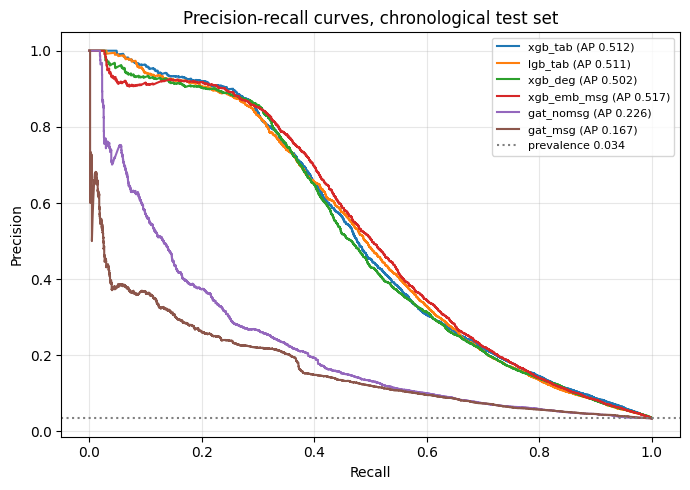

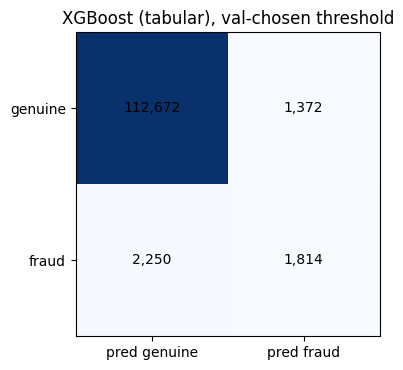

TN 112,672 | FP 1,372 | FN 2,250 | TP 1,814 | precision 0.569 | recall 0.446


In [10]:
# ═══ CELL 9: Figures: PR curves and confusion matrix (seed = first seed) ═══
s0 = CFG['SEEDS'][0]
show = [m for m in ['xgb_tab', 'lgb_tab', 'xgb_deg', 'xgb_rich', 'xgb_emb_msg', 'gat_nomsg', 'gat_msg'] if f'{m}|{s0}' in PREDS]
plt.figure(figsize=(7, 5))
for m in show:
    p, r, _ = precision_recall_curve(y_test, PREDS[f'{m}|{s0}'])
    plt.plot(r, p, label=f"{m} (AP {average_precision_score(y_test, PREDS[f'{m}|{s0}']):.3f})", lw=1.5)
plt.axhline(y_test.mean(), color='gray', ls=':', label=f'prevalence {y_test.mean():.3f}')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-recall curves, chronological test set')
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(CFG['OUT_DIR'], 'fig_pr_curves.png'), dpi=200); plt.show()

# Confusion matrix of tabular XGBoost at the threshold chosen on the validation slice
r_ = R[(R.model == 'xgb_tab') & (R.seed == s0)].iloc[0]
yhat = (PREDS[f'xgb_tab|{s0}'] >= r_['val_thr']).astype(int)
tp = int(((yhat == 1) & (y_test == 1)).sum()); fp = int(((yhat == 1) & (y_test == 0)).sum())
fn = int(((yhat == 0) & (y_test == 1)).sum()); tn = int(((yhat == 0) & (y_test == 0)).sum())
cm = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(4.2, 3.8)); ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f'{v:,}', ha='center', va='center', color='black')
ax.set_xticks([0, 1], ['pred genuine', 'pred fraud']); ax.set_yticks([0, 1], ['genuine', 'fraud'])
ax.set_title('XGBoost (tabular), val-chosen threshold'); plt.tight_layout()
plt.savefig(os.path.join(CFG['OUT_DIR'], 'fig_confusion_xgb_tab.png'), dpi=200); plt.show()
print(f'TN {tn:,} | FP {fp:,} | FN {fn:,} | TP {tp:,} | precision {tp/max(tp+fp,1):.3f} | recall {tp/max(tp+fn,1):.3f}')

 rank        feature         group  mean_abs_SHAP
    1            C13       tabular         0.3473
    2     GAT_emb_16 GAT embedding         0.2828
    3 TransactionAmt       tabular         0.2408
    4             C1       tabular         0.2276
    5            C14       tabular         0.2059
    6           V258       tabular         0.1746
    7     GAT_emb_25 GAT embedding         0.1681
    8            V70       tabular         0.1679
    9          card2       tabular         0.1661
   10             C5       tabular         0.1606
   11            C11       tabular         0.1497
   12          card1       tabular         0.1444
   13             D2       tabular         0.1355
   14     GAT_emb_14 GAT embedding         0.1302
   15             C2       tabular         0.1232
   16             D1       tabular         0.1211
   17          dist1       tabular         0.1146
   18      GAT_emb_2 GAT embedding         0.1113
   19            D15       tabular         0.1080


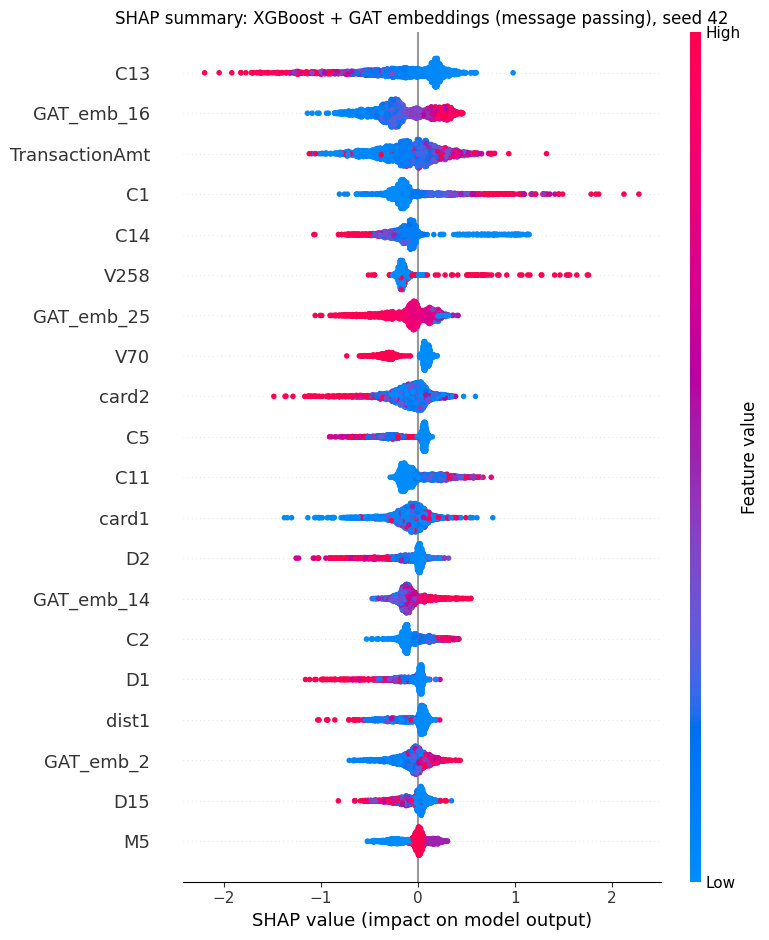

In [11]:
# ═══ CELL 10: SHAP on the hybrid model (needs RUN_GAT = True), with real feature names ═══
if os.path.exists(shap_model_path) and os.path.exists(shap_x_path):
    import shap
    booster = xgb.Booster(); booster.load_model(shap_model_path)
    X_samp = np.load(shap_x_path)
    names = tab_cols + [f'GAT_emb_{i}' for i in range(CFG['GAT_OUT'])]
    sv = shap.TreeExplainer(booster).shap_values(X_samp)
    if isinstance(sv, list): sv = sv[1]
    mean_abs = np.abs(sv).mean(axis=0); n_tab = len(tab_cols)
    top = np.argsort(-mean_abs)[:20]
    top_df = pd.DataFrame({'rank': range(1, 21), 'feature': [names[i] for i in top],
                           'group': ['tabular' if i < n_tab else 'GAT embedding' for i in top],
                           'mean_abs_SHAP': mean_abs[top].round(4)})
    print(top_df.to_string(index=False))
    print(f"\nGroup share of total attribution: tabular {mean_abs[:n_tab].sum()/mean_abs.sum():.1%} | "
          f"embeddings {mean_abs[n_tab:].sum()/mean_abs.sum():.1%}")
    print(f"Mean |SHAP| per feature: tabular {mean_abs[:n_tab].mean():.4f} | embedding {mean_abs[n_tab:].mean():.4f}")
    plt.figure(figsize=(10, 8))
    shap.summary_plot(sv, X_samp, feature_names=names, show=False, max_display=20)
    plt.title(f"SHAP summary: XGBoost + GAT embeddings (message passing), seed {CFG['GAT_SEEDS'][0]}")
    plt.tight_layout(); plt.savefig(os.path.join(CFG['OUT_DIR'], 'shap_summary_hybrid.png'), dpi=150, bbox_inches='tight'); plt.show()
    top_df.to_csv(os.path.join(CFG['OUT_DIR'], 'shap_top20.csv'), index=False)
else:
    print('No saved hybrid model (RUN_GAT=False or not finished yet): SHAP skipped.')

In [ ]:
# ═══ CELL 11: Saving everything + environment details for the thesis ═══
out = CFG['OUT_DIR']
R.to_csv(os.path.join(out, 'results_long.csv'), index=False)
summ.to_csv(os.path.join(out, 'summary_mean_sd.csv'))
deltas.to_csv(os.path.join(out, 'paired_deltas.csv'), index=False)
boot.to_csv(os.path.join(out, 'paired_bootstrap.csv'), index=False)
np.savez_compressed(os.path.join(out, 'test_predictions.npz'), y_test=y_test, **{k.replace('|', '__'): v for k, v in PREDS.items()})

env = {'python': sys.version.split()[0], 'platform': platform.platform(), 'machine': platform.machine(),
       'numpy': np.__version__, 'pandas': pd.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
       'config': CFG, 'n_rows': int(N), 'n_train_fit': int(val_start), 'n_val': int(split_idx - val_start), 'n_test': int(N - split_idx)}
try:
    import sklearn; env['scikit-learn'] = sklearn.__version__
    import psutil; env['ram_gb'] = round(psutil.virtual_memory().total / 1e9, 1); env['cpu_count'] = os.cpu_count()
except Exception: pass
if CFG['RUN_GAT']:
    import torch_geometric
    env['torch'] = torch.__version__; env['torch_geometric'] = torch_geometric.__version__
json.dump(env, open(os.path.join(out, 'environment.json'), 'w'), indent=2, default=str)
print(json.dumps({k: v for k, v in env.items() if k != 'config'}, indent=2, default=str))
print('\nSaved to', out)

{
  "python": "3.9.6",
  "platform": "macOS-26.5-arm64-arm-64bit",
  "machine": "arm64",
  "numpy": "2.0.2",
  "pandas": "2.3.3",
  "xgboost": "2.1.4",
  "lightgbm": "4.6.0",
  "n_rows": 590540,
  "n_train_fit": 425188,
  "n_val": 47244,
  "n_test": 118108,
  "scikit-learn": "1.6.1",
  "ram_gb": 17.2,
  "cpu_count": 10,
  "torch": "2.8.0",
  "torch_geometric": "2.6.1"
}

Saved to results_v2
